<a href="https://colab.research.google.com/github/paddycodesabit/Emerging-Digital-Methodologies-EDM-2025/blob/main/Running_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!pip install gensim
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
import string
import os

# Initialize NLTK stopwords
stop_words = set(stopwords.words('english'))

from tabulate import tabulate
import numpy as np
import pandas as pd
from scipy.spatial import distance
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
from scipy import spatial
import string
import gensim.downloader as api
import string
import string
import seaborn as sns
sns.set_theme()

# importing packages and data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
# Function to preprocess text
def preprocess(s):
    # Remove punctuation
    translator = str.maketrans('', '', string.punctuation)
    s = s.translate(translator)
    # Remove numbers
    translator = str.maketrans('', '', '0123456789')
    s = s.translate(translator)
    # Tokenize text
    tokens = word_tokenize(s)
    # Remove stop words and convert tokens to lowercase
    tokens = [token.lower() for token in tokens if token.lower() not in stop_words]
    # Stemming
    stemmer = PorterStemmer()
    stemmed_tokens = [stemmer.stem(token) for token in tokens]
    filtered_tokens = [stem for stem, token in zip(stemmed_tokens, tokens) if stem != token]
    return ' '.join(filtered_tokens)

# Function to read and preprocess a file
def read_and_preprocess(file_path):
    # Read the file
    with open(file_path, 'r', encoding='utf-8', errors='ignore') as file:
        text = file.read().replace('\n', ' ')
    # Preprocess the text
    preprocessed_text = preprocess(text)
    # Get the filename and construct the new filename for the preprocessed text
    filename = os.path.basename(file_path)
    new_filename = "data_PreP/PreP_" + filename
    # Write the preprocessed text to a new file
    with open(new_filename, 'w', encoding='utf-8') as new_file:
        new_file.write(preprocessed_text)
    return preprocessed_text

# List of file paths to process
file_paths = ["Beattie_PWJB.txt",
"Beattie_TMPG.txt",
    "Black_EOMA.txt",
    "Blair_LRBL.txt",
    "Blair_SERM.txt",
    "Boswell_TJTH.txt",
    "Boswell_TLSJ.txt",
    "Boswell_TLSJ(1).txt",
    "Bruce_TSNA.txt",
    "Bruce_TSNB.txt",
    "Bruce_TSNC.txt",
    "Bruce_TSND.txt",
    "Bruce_TSNE.txt",
    "Buchan_DOME.txt",
    "Buffon_NHGP.txt",
    "Burns_POEM.txt",
    "Camoes_TDOI.txt",
    "Campbell_ADOM.txt",
    "Dow_ZIAT.txt",
    "Dow_SEAT.txt",
    "Dow_THOH.txt",
    "Duncan_OOOM.txt",
    "Ferguson_AESI.txt",
    "Ferguson_EHCS.txt",
    "Fordyce_EOPP.txt",
    "Gerard_AEOT.txt",
    "Gerard_DIOC.txt",
    "Gerard_SERM.txt",
    "Gregory_FLHD.txt",
    "Hamilton_OTPM.txt",
    "Heron_LEOL.txt",
    "Home_AGIS.txt",
    "Home_ALFR.txt",
    "Home_ALON.txt",
    "Home_DOUG.txt",
    "Home_EOCR.txt",
    "Home_ERSL.txt",
    "Home_TFDI.txt",
    "Home_TGEF.txt",
    "Home_TPAV.txt",
    "Home_TSOA.txt",
    "Hume_DCNR.txt",
    "Hume_ECHU.txt",
    "Hume_ETVS.txt",
    "Hume_HOEH.txt",
    "Hume_HOEN.txt",
    "Hume_HPTS.txt",
    "Hume_PODI.txt",
    "Hume_POMO.txt",
    "Hume_THOETTAOHVII.txt",
    "Hume_THOETTRO1688.txt",
    "Hutcheson_ASIMP.txt",
    "Hutcheson_ASMP.txt",
    "Hutton_TOEA.txt",
    "Hutton_TOEB.txt",
    "Mackenzie_JDRO.txt",
    "Mackenzie_TMOF.txt",
    "Mackenzie_TMOF(1).txt",
    "Mackintosh_VIGA.txt",
    "Macpherson_AAEP.txt",
    "Macpherson_AAEP1.txt",
    "Macpherson_FOAP.txt",
    "Macpherson_THGB.txt",
    "Millar_AHVEG.txt",
    "Millar_TODR.txt",
    "Monro_ADBM.txt",
    "Moore_SMIA.txt",
    "Moore_SMIB.txt",
    "Moore_VSMA.txt",
    "Moore_VSMB.txt",
    "Ogilvie_ELPA.txt",
    "Park_TIDA.txt",
    "Pinkerton_AEHS.txt",
    "Pinkerton_RIME.txt",
    "Pinkerton_THOS.txt",
    "Pringle_ADTG.txt",
    "Robertson_HDKI.txt",
    "Robertson_HRCV.txt",
    "Robertson_THOA.txt",
    "Robertson_THOA910.txt",
    "Robertson_THOS.txt",
    "Smith_EOPS.txt",
    "Smith_INCW.txt",
    "Smith_TOMS.txt",
    "Smolett_HOEW.txt",
    "Smolett_AOLG.txt",
    "Smolett_AOPP.txt",
    "Smolett_AORR.txt",
    "Smolett_HOEV.txt",
    "Smolett_TAOF.txt",
    "Smolett_TTFI.txt",
    "Steuart_IPOE.txt",
    "Stuart_THOS.txt",
    "Thomas_CMGW.txt",
    "Tyler_EOPT.txt"
]

# Dictionary to store preprocessed texts
preprocessed_texts = {}

# Process each file and save preprocessed text
for file_path in file_paths:
    file_path = "/content/" + file_path
    preprocessed_texts[file_path] = read_and_preprocess(file_path)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [11]:
model = api.load("glove-wiki-gigaword-50") #choose from multiple models https://github.com/RaRe-Technologies/gensim-data

[==================================================] 100.0% 66.0/66.0MB downloaded


In [12]:
# List of file paths to process
preprocessed_texts = [
    "PreP_Beattie_PWJB.txt",
    "PreP_Beattie_TMPG.txt",
    "PreP_Black_EOMA.txt",
    "PreP_Blair_LRBL.txt",
    "PreP_Blair_SERM.txt",
    "PreP_Boswell_TJTH.txt",
    "PreP_Boswell_TLSJ.txt",
    "PreP_Boswell_TLSJ(1).txt",
    "PreP_Bruce_TSNA.txt",
    "PreP_Bruce_TSNB.txt",
    "PreP_Bruce_TSNC.txt",
    "PreP_Bruce_TSND.txt",
    "PreP_Bruce_TSNE.txt",
    "PreP_Buchan_DOME.txt",
    "PreP_Buffon_NHGP.txt",
    "PreP_Burns_POEM.txt",
    "PreP_Camoes_TDOI.txt",
    "PreP_Campbell_ADOM.txt",
    "PreP_Dow_ZIAT.txt",
    "PreP_Dow_SEAT.txt",
    "PreP_Dow_THOH.txt",
    "PreP_Duncan_OOOM.txt",
    "PreP_Ferguson_AESI.txt",
    "PreP_Ferguson_EHCS.txt",
    "PreP_Fordyce_EOPP.txt",
    "PreP_Gerard_AEOT.txt",
    "PreP_Gerard_DIOC.txt",
    "PreP_Gerard_SERM.txt",
    "PreP_Gregory_FLHD.txt",
    "PreP_Hamilton_OTPM.txt",
    "PreP_Heron_LEOL.txt",
    "PreP_Home_AGIS.txt",
    "PreP_Home_ALFR.txt",
    "PreP_Home_ALON.txt",
    "PreP_Home_DOUG.txt",
    "PreP_Home_EOCR.txt",
    "PreP_Home_ERSL.txt",
    "PreP_Home_TFDI.txt",
    "PreP_Home_TGEF.txt",
    "PreP_Home_TPAV.txt",
    "PreP_Home_TSOA.txt",
    "PreP_Hume_DCNR.txt",
    "PreP_Hume_ECHU.txt",
    "PreP_Hume_ETVS.txt",
    "PreP_Hume_HOEH.txt",
    "PreP_Hume_HOEN.txt",
    "PreP_Hume_HPTS.txt",
    "PreP_Hume_PODI.txt",
    "PreP_Hume_POMO.txt",
    "PreP_Hume_THOETTAOHVII.txt",
    "PreP_Hume_THOETTRO1688.txt",
    "PreP_Hutcheson_ASIMP.txt",
    "PreP_Hutcheson_ASMP.txt",
    "PreP_Hutton_TOEA.txt",
    "PreP_Hutton_TOEB.txt",
    "PreP_Mackenzie_JDRO.txt",
    "PreP_Mackenzie_TMOF.txt",
    "PreP_Mackenzie_TMOF(1).txt",
    "PreP_Mackintosh_VIGA.txt",
    "PreP_Macpherson_AAEP.txt",
    "PreP_Macpherson_AAEP1.txt",
    "PreP_Macpherson_FOAP.txt",
    "PreP_Macpherson_THGB.txt",
    "PreP_Millar_AHVEG.txt",
    "PreP_Millar_TODR.txt",
    "PreP_Monro_ADBM.txt",
    "PreP_Moore_SMIA.txt",
    "PreP_Moore_SMIB.txt",
    "PreP_Moore_VSMA.txt",
    "PreP_Moore_VSMB.txt",
    "PreP_Ogilvie_ELPA.txt",
    "PreP_Park_TIDA.txt",
    "PreP_Pinkerton_AEHS.txt",
    "PreP_Pinkerton_RIME.txt",
    "PreP_Pinkerton_THOS.txt",
    "PreP_Pringle_ADTG.txt",
    "PreP_Robertson_HDKI.txt",
    "PreP_Robertson_HRCV.txt",
    "PreP_Robertson_THOA.txt",
    "PreP_Robertson_THOA910.txt",
    "PreP_Robertson_THOS.txt",
    "PreP_Smith_EOPS.txt",
    "PreP_Smith_INCW.txt",
    "PreP_Smith_TOMS.txt",
    "PreP_Smolett_AOLG.txt",
    "PreP_Smolett_AOPP.txt",
    "PreP_Smolett_AORR.txt",
    "PreP_Smolett_HOEV.txt",
    "PreP_Smolett_HOEW.txt",
    "PreP_Smolett_TAOF.txt",
    "PreP_Smolett_TTFI.txt",
    "PreP_Steuart_IPOE.txt",
    "PreP_Stuart_THOS.txt",
    "PreP_Thomas_CMGW.txt",
    "PreP_Tyler_EOPT.txt"]

#print(len(preprocessed_texts))


# TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer()

# Fit and transform the corpus
corpus = []

# Append preprocessed texts to the corpus
for preprocessed_text in preprocessed_texts:
    # Read the file
    with open("data_PreP/" + preprocessed_text, 'r', encoding='utf-8', errors='ignore') as file:
      text = file.read().replace('\n', ' ')
    corpus.append(text)

# Compute TF-IDF matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)

In [13]:
# Get vectors using the pre-trained GloVe model
def get_vector(s):
    tokens = word_tokenize(s)
    vectors = []
    for token in tokens:
        if token in model.key_to_index:
            vectors.append(model[token])
    if vectors:
        return np.sum(np.array(vectors), axis=0)
    else:
        return np.zeros_like(model["hello"])  # Return a zero vector if no valid word vectors are found

# Cosine similarity with normalized vectors
def cosine_similarity(vec1, vec2):
    vec1_normalized = vec1 / np.linalg.norm(vec1)
    vec2_normalized = vec2 / np.linalg.norm(vec2)
    return np.dot(vec1_normalized, vec2_normalized)

# Calculate similarities
results = []
for i in range(len(corpus)):
  for j in range(i, len(corpus)) :
    sim = cosine_similarity(get_vector(corpus[i]), get_vector(corpus[j]))
    results.append([preprocessed_texts[i], preprocessed_texts[j], sim])

# Sort results based on similarity coefficients in descending order
results.sort(key=lambda x: x[2], reverse=True)

# Print table
print(tabulate(results, headers=["Text File 1", "Text File 2", "Cosine Similarity"]))

Text File 1                 Text File 2                   Cosine Similarity
--------------------------  --------------------------  -------------------
PreP_Campbell_ADOM.txt      PreP_Campbell_ADOM.txt                 1
PreP_Beattie_TMPG.txt       PreP_Beattie_TMPG.txt                  1
PreP_Boswell_TLSJ.txt       PreP_Boswell_TLSJ.txt                  1
PreP_Dow_SEAT.txt           PreP_Dow_SEAT.txt                      1
PreP_Dow_THOH.txt           PreP_Dow_THOH.txt                      1
PreP_Fordyce_EOPP.txt       PreP_Fordyce_EOPP.txt                  1
PreP_Gerard_AEOT.txt        PreP_Gerard_AEOT.txt                   1
PreP_Gerard_SERM.txt        PreP_Gerard_SERM.txt                   1
PreP_Home_AGIS.txt          PreP_Home_AGIS.txt                     1
PreP_Home_ALFR.txt          PreP_Home_ALFR.txt                     1
PreP_Home_DOUG.txt          PreP_Home_DOUG.txt                     1
PreP_Home_EOCR.txt          PreP_Home_EOCR.txt                     1
PreP_Hume_POMO.txt  

(array([  1.,   0.,   1.,   1.,   0.,   1.,   1.,   1.,   2.,   5.,   7.,
         12.,  23.,  24.,  21.,  27.,  30.,  51.,  35.,  58.,  71.,  74.,
         89.,  92., 110., 119., 114., 162., 164., 191., 208., 227., 285.,
        338., 409., 452., 416., 338., 238., 162.]),
 array([0.4437966 , 0.45770168, 0.47160679, 0.48551187, 0.49941698,
        0.51332206, 0.52722716, 0.54113221, 0.55503732, 0.56894243,
        0.58284748, 0.59675258, 0.61065769, 0.6245628 , 0.63846785,
        0.65237296, 0.66627806, 0.68018317, 0.69408822, 0.70799333,
        0.72189844, 0.73580348, 0.74970859, 0.7636137 , 0.77751875,
        0.79142386, 0.80532897, 0.81923401, 0.83313912, 0.84704423,
        0.86094928, 0.87485445, 0.88875949, 0.90266454, 0.91656971,
        0.93047476, 0.94437981, 0.95828497, 0.97219002, 0.98609507,
        1.00000024]),
 <BarContainer object of 40 artists>)

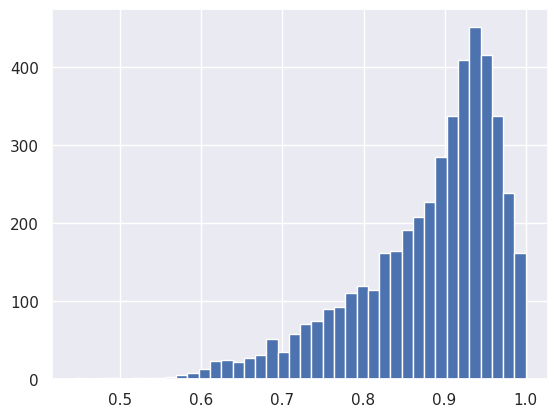

In [14]:
import matplotlib.pyplot as plt
plt.hist([sublist[2] for sublist in results], bins = 40)

In [15]:
print(type(results))
print(type(results[0]))

<class 'list'>
<class 'list'>


In [16]:
print(type(results))
print(type(results[0]))

<class 'list'>
<class 'list'>


In [17]:
# Extract unique labels
x_labels = sorted(set(item[0] for item in results))
y_labels = sorted(set(item[1] for item in results))

# Create a dictionary to map labels to indices
label_to_index = {label: idx for idx, label in enumerate(x_labels)}

# Initialize the matrix with NaNs (or zeros)
size = len(x_labels)
A = np.full((size, size), np.nan)

# Fill the matrix with the provided values
for x_label, y_label, value in results:
    x_idx = label_to_index[x_label]
    y_idx = label_to_index[y_label]
    A[x_idx, y_idx] = value
    A[y_idx, x_idx] = value  # Ensure symmetry

np.fill_diagonal(A, 0)
np.save('A.npy', A)

In [18]:
A = np.load('A.npy')
print(A)

[[0.         0.99276692 0.76429087 ... 0.71189177 0.83667797 0.85432225]
 [0.99276692 0.         0.77676338 ... 0.73007458 0.84572446 0.84124464]
 [0.76429087 0.77676338 0.         ... 0.84956479 0.87800688 0.84002137]
 ...
 [0.71189177 0.73007458 0.84956479 ... 0.         0.92460066 0.85919368]
 [0.83667797 0.84572446 0.87800688 ... 0.92460066 0.         0.93749702]
 [0.85432225 0.84124464 0.84002137 ... 0.85919368 0.93749702 0.        ]]


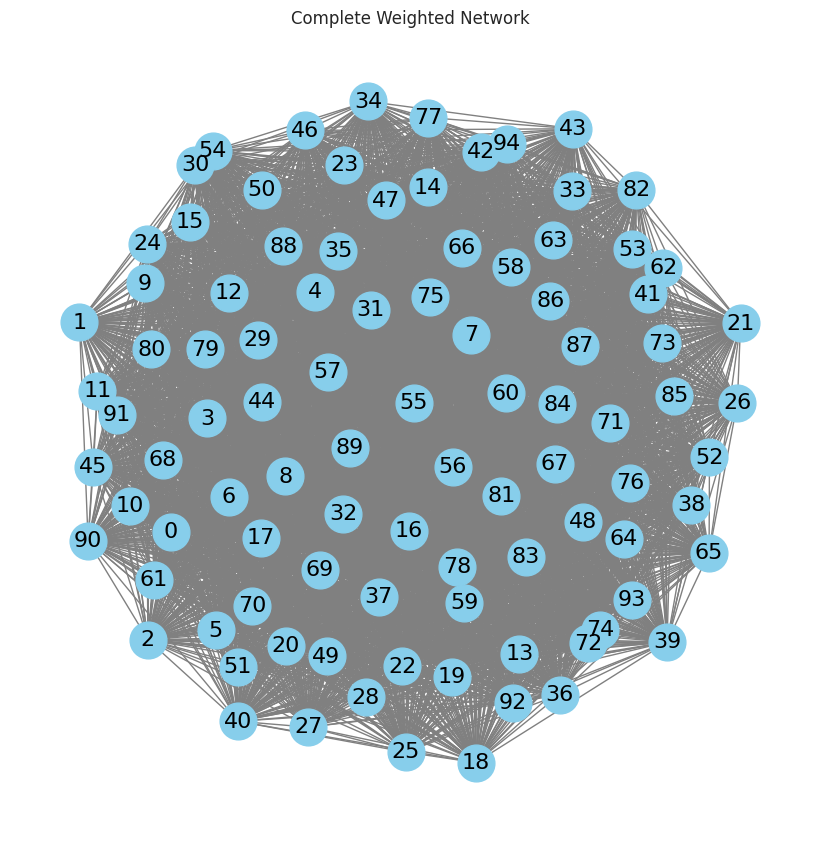

In [19]:
G = nx.from_numpy_array(A)

# Draw the graph
plt.figure(figsize=(8, 8))
nx.draw(G, with_labels = True,
        node_size = 700,
        node_color = "skyblue",
        font_size = 16,
        font_color = "black",
        edge_color = "gray")
plt.title("Complete Weighted Network")
plt.show()

In [20]:
degree = {v: sum(d['weight'] for u, v, d in G.edges(v, data=True)) for v in G.nodes()}

# Print the top 5 nodes with highest degree
sorted_nodes = sorted(degree, key = degree.get, reverse = True)
print("Top 5 nodes with degree:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Degree = {degree[sorted_nodes[i]]}")

print("\n")

# Print the top 5 nodes with lowest degree
sorted_nodes = sorted(degree, key = degree.get, reverse = False)
print("Top 5 nodes with lowest degree:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Degree = {degree[sorted_nodes[i]]}")

Top 5 nodes with degree:
Node 68: Degree = 87.59601771831512
Node 69: Degree = 87.46860009431839
Node 67: Degree = 87.3662719130516
Node 66: Degree = 87.16737532615662
Node 93: Degree = 86.71273517608643


Top 5 nodes with lowest degree:
Node 72: Degree = 62.0766199529171
Node 54: Degree = 63.35278940200806
Node 18: Degree = 69.89920127391815
Node 27: Degree = 71.0619558095932
Node 25: Degree = 71.56445500254631


In [21]:
pagerank = nx.pagerank(G)

# Print the top 5 nodes with highest pagerank
sorted_nodes = sorted(pagerank, key = pagerank.get, reverse = True)
print("Top 5 nodes with highest pagerank:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Pagerank = {pagerank[sorted_nodes[i]]}")

print("\n")

sorted_nodes = sorted(pagerank, key = pagerank.get, reverse = False)
# Print the top 5 nodes with lowest pagerank
print("Top 5 nodes with lowest pagerank:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Pagerank = {pagerank[sorted_nodes[i]]}")

Top 5 nodes with highest pagerank:
Node 68: Pagerank = 0.011076610217344948
Node 69: Pagerank = 0.011062931617418066
Node 67: Pagerank = 0.011052042786032692
Node 66: Pagerank = 0.011029854857979622
Node 93: Pagerank = 0.010980797301029773


Top 5 nodes with lowest pagerank:
Node 72: Pagerank = 0.008307262100126523
Node 54: Pagerank = 0.008448826021960449
Node 18: Pagerank = 0.009160206531445905
Node 27: Pagerank = 0.009285106625015286
Node 25: Pagerank = 0.00933634720561861


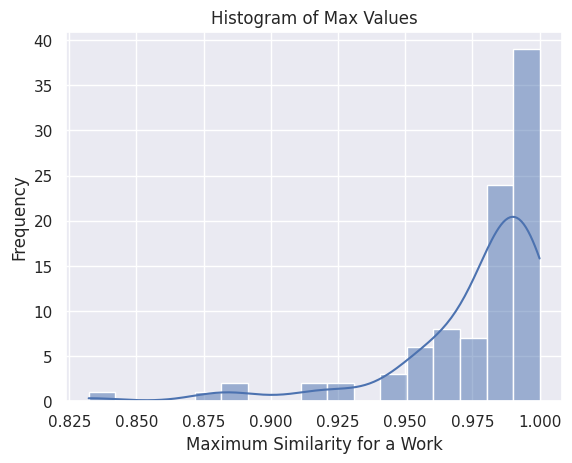

In [22]:
max_values = np.max(A, axis=0).tolist()
sns.histplot(max_values, kde = True)

plt.title('Histogram of Max Values')
plt.xlabel('Maximum Similarity for a Work')
plt.ylabel('Frequency')

# Show the plot
plt.show()

In [23]:
print("Minmax threshold")
print(min(max_values))

A_2 = (A >= min(max_values)).astype(int)
print(A_2)

Minmax threshold
0.8322091102600098
[[0 1 0 ... 0 1 1]
 [1 0 0 ... 0 1 1]
 [0 0 0 ... 1 1 1]
 ...
 [0 0 1 ... 0 1 1]
 [1 1 1 ... 1 0 1]
 [1 1 1 ... 1 1 0]]


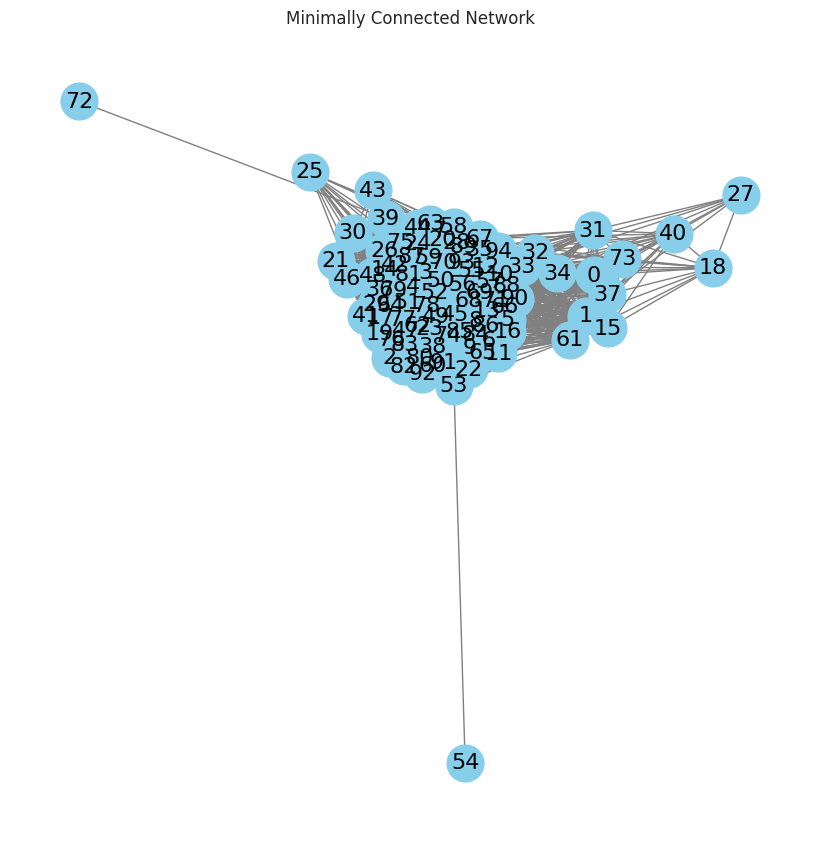

In [24]:
G = nx.from_numpy_array(A_2)

# Draw the graph
plt.figure(figsize=(8, 8))
nx.draw(G, with_labels = True,
        node_size = 700,
        node_color = "skyblue",
        font_size = 16,
        font_color = "black",
        edge_color = "gray")
plt.title("Minimally Connected Network")
plt.show()

In [25]:
degree = nx.degree_centrality(G)

# Print the top 5 nodes with highest degree
sorted_nodes = sorted(degree, key = degree.get, reverse = True)
print("Top 5 nodes with degree:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Degree = {degree[sorted_nodes[i]]}")

print("\n")

# Print the top 5 nodes with lowest degree
sorted_nodes = sorted(degree, key = degree.get, reverse = False)
print("Top 5 nodes with lowest degree:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Degree = {degree[sorted_nodes[i]]}")

Top 5 nodes with degree:
Node 35: Degree = 0.9468085106382979
Node 55: Degree = 0.9361702127659575
Node 56: Degree = 0.9361702127659575
Node 67: Degree = 0.9361702127659575
Node 68: Degree = 0.9361702127659575


Top 5 nodes with lowest degree:
Node 54: Degree = 0.010638297872340425
Node 72: Degree = 0.010638297872340425
Node 27: Degree = 0.0851063829787234
Node 18: Degree = 0.13829787234042554
Node 25: Degree = 0.1702127659574468


In [26]:
betweenness = nx.betweenness_centrality(G)

# Print the top 5 nodes with highest betweenness
sorted_nodes = sorted(betweenness, key = betweenness.get, reverse = True)
print("Top 5 nodes with highest betweenness:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Betweenness = {betweenness[sorted_nodes[i]]}")

print("\n")

# Print the top 5 nodes with lowest betweenness
sorted_nodes = sorted(betweenness, key = betweenness.get, reverse = False)
print("Top 5 nodes with lowest betweenness:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Betweenness = {betweenness[sorted_nodes[i]]}")

Top 5 nodes with highest betweenness:
Node 20: Betweenness = 0.024590347705151314
Node 53: Betweenness = 0.021753311318609386
Node 33: Betweenness = 0.01628755191077985
Node 94: Betweenness = 0.015172213984166278
Node 32: Betweenness = 0.010173284045186172


Top 5 nodes with lowest betweenness:
Node 25: Betweenness = 0.0
Node 27: Betweenness = 0.0
Node 54: Betweenness = 0.0
Node 72: Betweenness = 0.0
Node 21: Betweenness = 3.2682942772167206e-06


In [27]:
pagerank = nx.pagerank(G)

# Print the top 5 nodes with highest pagerank
sorted_nodes = sorted(pagerank, key = pagerank.get, reverse = True)
print("Top 5 nodes with highest pagerank:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Pagerank = {pagerank[sorted_nodes[i]]}")

print("\n")

sorted_nodes = sorted(pagerank, key = pagerank.get, reverse = False)
# Print the top 5 nodes with lowest pagerank
print("Top 5 nodes with lowest pagerank:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Pagerank = {pagerank[sorted_nodes[i]]}")

Top 5 nodes with highest pagerank:
Node 94: Pagerank = 0.013056570513391179
Node 35: Pagerank = 0.01299791245849329
Node 55: Pagerank = 0.012808482505207847
Node 56: Pagerank = 0.012808482505207847
Node 67: Pagerank = 0.012808482505207847


Top 5 nodes with lowest pagerank:
Node 54: Pagerank = 0.0017190415768231168
Node 72: Pagerank = 0.0017200735542655505
Node 27: Pagerank = 0.0029409042253895727
Node 25: Pagerank = 0.003573889741323796
Node 18: Pagerank = 0.003735189738275786


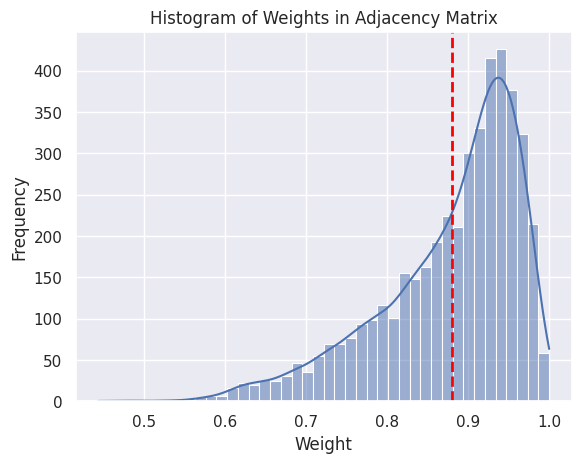

In [28]:
weights = A[np.triu_indices(A.shape[0], k=1)]

# Plotting histogram of weights
sns.histplot(weights, kde = True)
plt.axvline(x = .88,
            color = 'red',
            linestyle = '--',
            linewidth = 2)
plt.xlabel('Weight')
plt.ylabel('Frequency')
plt.title('Histogram of Weights in Adjacency Matrix')
plt.show()

[[0 1 0 ... 0 0 0]
 [1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 1 0]
 [0 0 0 ... 1 0 1]
 [0 0 0 ... 0 1 0]]


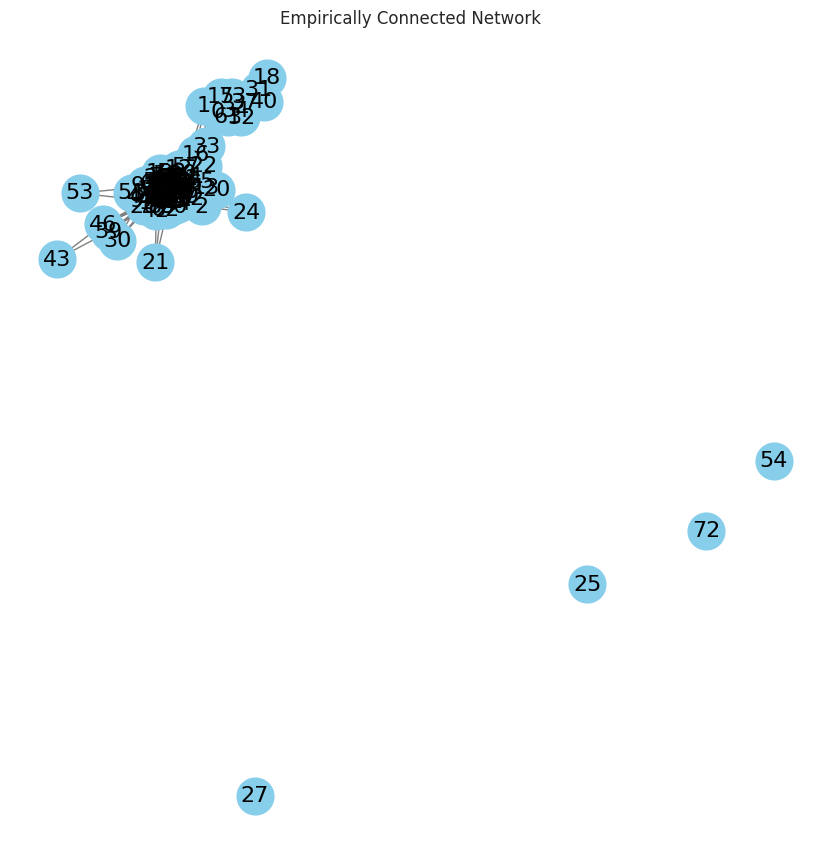

In [29]:
A_3 = (A >= .91).astype(int)
print(A_3)

G = nx.from_numpy_array(A_3)

# Draw the graph
plt.figure(figsize = (8, 8))
nx.draw(G, with_labels = True,
        node_size = 700,
        node_color = "skyblue",
        font_size = 16,
        font_color = "black",
        edge_color = "gray")
plt.title("Empirically Connected Network")
plt.show()

In [30]:
degree = nx.degree_centrality(G)

# Print the top 5 nodes with highest degree
sorted_nodes = sorted(degree, key = degree.get, reverse = True)
print("Top 5 nodes with degree:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Degree = {degree[sorted_nodes[i]]}")

print("\n")

# Print the top 5 nodes with lowest degree
sorted_nodes = sorted(degree, key = degree.get, reverse = False)
print("Top 5 nodes with lowest degree:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Degree = {degree[sorted_nodes[i]]}")

Top 5 nodes with degree:
Node 67: Degree = 0.7553191489361702
Node 68: Degree = 0.7553191489361702
Node 66: Degree = 0.7446808510638298
Node 69: Degree = 0.7446808510638298
Node 35: Degree = 0.7234042553191489


Top 5 nodes with lowest degree:
Node 25: Degree = 0.0
Node 27: Degree = 0.0
Node 54: Degree = 0.0
Node 72: Degree = 0.0
Node 43: Degree = 0.02127659574468085


In [31]:
betweenness = nx.betweenness_centrality(G)

# Print the top 5 nodes with highest betweenness
sorted_nodes = sorted(betweenness, key = betweenness.get, reverse = True)
print("Top 5 nodes with highest betweenness:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Betweenness = {betweenness[sorted_nodes[i]]}")

print("\n")

# Print the top 5 nodes with lowest betweenness
sorted_nodes = sorted(betweenness, key = betweenness.get, reverse = False)
print("Top 5 nodes with lowest betweenness:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Betweenness = {betweenness[sorted_nodes[i]]}")

Top 5 nodes with highest betweenness:
Node 57: Betweenness = 0.07216768353435864
Node 16: Betweenness = 0.0662629472172604
Node 33: Betweenness = 0.06221583137219474
Node 70: Betweenness = 0.02799769073509785
Node 35: Betweenness = 0.020095287738192354


Top 5 nodes with lowest betweenness:
Node 21: Betweenness = 0.0
Node 24: Betweenness = 0.0
Node 25: Betweenness = 0.0
Node 27: Betweenness = 0.0
Node 30: Betweenness = 0.0


In [32]:
pagerank = nx.pagerank(G)

# Print the top 5 nodes with highest pagerank
sorted_nodes = sorted(pagerank, key = pagerank.get, reverse = True)
print("Top 5 nodes with highest pagerank:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Pagerank = {pagerank[sorted_nodes[i]]}")

print("\n")

sorted_nodes = sorted(pagerank, key = pagerank.get, reverse = False)
# Print the top 5 nodes with lowest pagerank
print("Top 5 nodes with lowest pagerank:")
for i in range(5):
    print(f"Node {sorted_nodes[i]}: Pagerank = {pagerank[sorted_nodes[i]]}")

Top 5 nodes with highest pagerank:
Node 70: Pagerank = 0.015351438582344567
Node 67: Pagerank = 0.0153509589218242
Node 68: Pagerank = 0.0153509589218242
Node 35: Pagerank = 0.015259950061603751
Node 66: Pagerank = 0.015159176779949733


Top 5 nodes with lowest pagerank:
Node 25: Pagerank = 0.0016375545851528386
Node 27: Pagerank = 0.0016375545851528386
Node 54: Pagerank = 0.0016375545851528386
Node 72: Pagerank = 0.0016375545851528386
Node 53: Pagerank = 0.0020520248504872387
